In [1]:
import csv
import numpy as np

def read_csv_numeric(path):
    # 1) read header for the name→index mapping
    with open(path, newline='', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader)
    col_idx = {name: i for i, name in enumerate(header)}

    # 2) load the rest as a 2D float array (missing -> NaN)
    # reopen so the file pointer is at the top again
    data = np.genfromtxt(
        path,
        delimiter=",",
        skip_header=1,
        dtype=float,
        missing_values=["", "NA", "NaN"],
        filling_values=np.nan
    )
    # If the CSV has only one data row, genfromtxt returns 1D; force 2D
    if data.ndim == 1:
        data = data.reshape(1, -1)

    return col_idx, data

In [2]:
x_indices, x_data = read_csv_numeric("../dataset/x_train.csv")
y_indices, y_data = read_csv_numeric("../dataset/y_train.csv")

In [3]:
# we select interesting columns and clean the dataset

import matplotlib.pyplot as plt

interesting_columns = ["QLACTLM2","_MISFRTN","_FRUITEX","_RFSEAT2","DRNKANY5","WTKG3","TRNSGNDR","FLUSHOT6","ORNGDAY_","PAFREQ2_","INCOME2","_VEGESUM","CHECKUP1","_VEGETEX","MAXVO2_","CHCOCNCR","_MINAC11","HIVTST6","VETERAN3","SEX","DRNK3GE5","LMTJOIN3","DIFFALON","_RACE_G1","_BMI5","BPHIGH4","FC60_","CHOLCHK","PADUR1_","MEDCOST","_LMTACT1","_SMOKER3","METVL11_","PADUR2_","FRUTDA1_","STRFREQ_","PHYSHLTH","GENHLTH","_PASTRNG","PERSDOC2","POORHLTH","_LMTSCL1","DECIDE","_PAINDX1","_MINAC21","_MISVEGN","VEGEDA1_","ADDEPEV2","CHCSCNCR","BPMEDS","HTM4","DIFFDRES","SXORIENT","PAMIN11_","_DRNKWEK","ALCDAY5","_PACAT1","EXERANY2","DIFFWALK","USEEQUIP","MENTHLTH","EMPLOY1","EXRACT11","TOLDHI2","AVEDRNK2","PAVIG21_","CHCKIDNY","_FRUTSUM","PA1MIN_","_ASTHMS1","DROCDY3_","HAVARTH3","_LMTWRK1","FLSHTMY2","PAVIG11_","PAMIN21_","GRENDAY_","ARTHDIS2","METVL21_","ARTHSOCL","PAMISS1_","_RFHLTH","BLIND","FRUIT1","_TOTINDA","JOINPAIN","DIABETE3","_PASTAE1","_MRACE1","_PAREC1","SMOKDAY2","SMOKE100","MSCODE","PA1VIGM_","BEANDAY_","_AGE80","USENOW3","BLOODCHO","PNEUVAC3","PAFREQ1_","CVDSTRK3","CHCCOPD1","EXRACT21","_CASTHM1","_AIDTST3","MAXDRNKS"

                        ]

# 6-digit: DK/Ref codes like 777777 / 999999
six_digit = [
    'FLSHTMY2',
    'HIVTSTD3',
]

# 5-digit: DK/Ref codes like 99999 (e.g., WTKG3)
five_digit = [
    'PA1VIGM_',
    'PAFREQ2_',
    'WTKG3',
]

# 4-digit: DK/Ref codes like 7777 / 9999 (e.g., WEIGHT2)
four_digit = [
    'AVEDRNK2',
    'BEANDAY_',
    'FRUTDA1_',
    'FTJUDA1_',
    'GRENDAY_',
    'HEIGHT3',
    'ORNGDAY_',
    'VEGEDA1_',
    'WEIGHT2',
    '_BMI5',
    '_BMI5CAT',
    '_RFBMI5',
]

# 3-digit: DK/Ref codes like 777 / 999 (e.g., ALCDAY5)
triple_digit = [
    'ALCDAY5',
    'ASACTLIM',
    'ASNOSLEP',
    'BLDSUGAR',
    'CDHELP',
    'DRNK3GE5',
    'DRNKANY5',
    'EXERHMM1',
    'EXERHMM2',
    'EXEROFT1',
    'EXEROFT2',
    'FEETCHK2',
    'FRUIT1',
    'FRUITJU1',
    'FVBEANS',
    'FVGREEN',
    'FVORANG',
    'LONGWTCH',
    'MAXDRNKS',
    'STRENGTH',
    'VEGETAB1',
    '_LMTSCL1',
    '_RFBING5',
]

# 2-digit: DK/Ref codes like 77 / 99 (e.g., DRNK3GE5)
double_digit = [
    'ADANXEV','ADDOWN','ADEAT1','ADENERGY','ADFAIL','ADMOVE','ADPLEASR','ADSLEEP','ADTHINK','ARTHSOCL',
    'ARTTODAY','ASINHALR','ASRCHKUP','ASTHMAGE','CAREGIV1','CASTHDX2','CDDISCUS','CDSOCIAL','CHKHEMO3','CRGVEXPT',
    'CRGVHOUS','CRGVPERS','CRGVPRB1','CRGVREL1','CVDINFR4','DIABAGE2','DIABETE3','DOCTDIAB','EMTSUPRT','EXRACT11',
    'EXRACT21','FC60_','FEETCHK','HAREHAB1','HHADULT','HOWLONG','HPVADVC2','IMFVPLAC','INCOME2','JOINPAIN',
    'LASTSIG3','LASTSMK2','LENGEXAM','LSTBLDS3','MAXVO2_','MENTHLTH','PAFREQ1_','PERSDOC2','PHYSHLTH','POORHLTH',
    'PSATIME','RDUCHART','SCNTLWK1','SCNTWRK1','SXORIENT','TRNSGNDR','VETERAN3','VINOCRE2','WHRTST10','_ASTHMS1',
    '_CRACE1','_DRDXAR1','_EDUCAG','_PNEUMO2','_PRACE1','_RACE','_RACE_G1','_WT2RAKE',
]

# 1-digit: DK/Ref codes like 7 / 9 (e.g., EXERANY2)
single_digit = [
    'ADDEPEV2','ARTHDIS2','ARTHEDU','ARTHEXER','ARTHWGT','ASATTACK','ASDRVIST','ASERVIST','ASPUNSAF','ASTHMA3','ASTHMED3','ASYMPTOM',
    'BLDSTOOL','BLIND','BLOODCHO','BPHIGH4','CASTHNO2','CDASSIST','CDHOUSE','CHCCOPD1','CHCKIDNY','CHECKUP1','CHOLCHK','CIMEMLOS',
    'CPDEMO1','CRGVHRS1','CRGVMST2','DECIDE','DIABEDU','DIABEYE','DIFFALON','DRADVISE','EDUCA','EXERANY2','EYEEXAM','FLUSHOT6',
    'HADHYST2','HADMAM','HADPAP2','HADSGCO1','HADSIGM3','HAVARTH3','HIVTST6','HLTHPLN1','HPVADSHT','HPVTEST','LANDLINE','LMTJOIN3',
    'MEDCOST','MISTMNT','NUMHHOL2','PCPSAAD2','PCPSADE1','PCPSADI1','PCPSARE1','PDIABTST','PNEUVAC3','PREDIAB1','PROFEXAM','QLACTLM2',
    'RENTHOM1','SCNTLPAD','SCNTMEL1','SCNTMNY1','SCNTPAID','SEATBELT','SMOKE100','STOPSMK2','STREHAB1','STRFREQ_','TETANUS','TOLDHI2',
    'USEEQUIP','USENOW3','VICTRCT4','VIDFCLT2','VIEYEXM2','VIGLUMA2','VIMACDG2','VIPRFVS2','VIREDIF3','WTCHSALT','_CHOLCHK','_HCVU651',
    '_LLCPWT','_LMTACT1','_MICHD','_PA150R2','_PA30021','_PA300R2','_PASTRNG','_RACEG21','_RFCHOL','_RFDRHV5','_RFHYPE5','_RFSEAT2',
    '_SMOKER3','_TOTINDA','_VEGESUM',
]

# No explicit DK/Ref "7…/9…" code in that variable’s own table
no_dk_rf = [
    'ACTIN11_','ACTIN21_','ASTHNOW','BPMEDS','CADULT','CCLGHOUS','CELLFON2','CELLFON3','CHCOCNCR','CHCSCNCR',
    'CHILDREN','COLGHOUS','CRGVLNG1','CSTATE','CTELENUM','CTELNUM1','CVDASPRN','CVDCRHD4','CVDSTRK3','DIFFDRES',
    'DIFFWALK','DISPCODE','DROCDY3_','EMPLOY1','EXACTOT1','EXACTOT2','EXRACT11','EXRACT21','FMONTH','GENHLTH',
    'HPLSTTST','HTIN4','HTM4','IDATE','IDAY','IMONTH','INSULIN','INTERNET','IYEAR','LADULT',
    'LASTPAP2','LSATISFY','MARITAL','METVL11_','METVL21_','MSCODE','NUMADULT','NUMMEN','NUMPHON2','NUMWOMEN',
    'PA1MIN_','PADUR1_','PADUR2_','PAINACT2','PAMIN11_','PAMIN21_','PAMISS1_','PAVIG11_','PAVIG21_','PCDMDECN',
    'PCPSARS1','PREGNANT','PSATEST1','PVTRESD1','PVTRESD2','QLHLTH2','QLMENTL2','QLSTRES2','QSTLANG','QSTVER',
    'RCSGENDR','RCSRLTN2','RDUCSTRK','RLIVPAIN','SEQNO','SEX','SHINGLE2','SMOKDAY2','STATERES','VIINSUR2',
    '_AGE65YR','_AGE80','_AGEG5YR','_AGE_G','_AIDTST3','_CASTHM1','_CHISPNC','_CHLDCNT','_CLLCPWT','_CPRACE',
    '_DRNKWEK','_DUALCOR','_DUALUSE','_FLSHOT6','_FRT16','_FRTLT1','_FRTRESP','_FRUITEX','_FRUTSUM','_HISPANC',
    '_INCOMG','_LMTWRK1','_LTASTH1','_MINAC11','_MINAC21','_MISFRTN','_MISVEGN','_MRACE1','_PACAT1','_PAINDX1',
    '_PAREC1','_PASTAE1','_PSU','_RACEGR3','_RAWRAKE','_RFHLTH','_RFSEAT3','_RFSMOK3','_STATE','_STRWT',
    '_STSTR','_VEG23','_VEGETEX','_VEGLT1','_VEGRESP',
]


for c in interesting_columns:
    if c in single_digit:
        x_data[x_data[:, x_indices[c]] == 7, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9, x_indices[c]] = np.nan
    elif c in double_digit:
        x_data[x_data[:, x_indices[c]] == 77, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99, x_indices[c]] = np.nan
    elif c in triple_digit:
        x_data[x_data[:, x_indices[c]] == 777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999, x_indices[c]] = np.nan
    elif c in four_digit:
        x_data[x_data[:, x_indices[c]] == 7777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9999, x_indices[c]] = np.nan
    elif c in five_digit:
        x_data[x_data[:, x_indices[c]] == 77777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99999, x_indices[c]] = np.nan
    elif c in six_digit:
        x_data[x_data[:, x_indices[c]] == 777777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999999, x_indices[c]] = np.nan
    else:
        if c not in no_dk_rf: 
            raise Exception("Not in any group", c)
    
x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] * 0.453592
x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] - 9000
x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]] = ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) // 100) * 30.48 + ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) % 100) * 2.54
x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] = x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] - 9000
x_data[x_data[:, x_indices["WEIGHT2"]] > 200, x_indices["WEIGHT2"]] = np.nan

In [4]:
# --- Keep only the columns of interest ---
x_data_interested = x_data[:, [x_indices[col] for col in interesting_columns]]
x_indices_interested = {col: i for i, col in enumerate(interesting_columns)}

# --- Drop columns that are all NaN ---
valid_cols = ~np.isnan(x_data_interested).all(axis=0)
x_data_interested = x_data_interested[:, valid_cols]
interesting_columns = [col for col, keep in zip(interesting_columns, valid_cols) if keep]
x_indices_interested = {col: i for i, col in enumerate(interesting_columns)}

# --- Impute remaining NaNs with column mean ---
col_mean = np.nanmean(x_data_interested, axis=0)
inds = np.where(np.isnan(x_data_interested))
x_data_interested[inds] = np.take(col_mean, inds[1])

# --- Standardize once ---
x_data_interested = (x_data_interested - np.mean(x_data_interested, axis=0)) / np.std(x_data_interested, axis=0)

# --- Prepare y ---
y = y_data[:,1].copy()
y[np.isnan(y)] = np.nanmean(y)
y = (y + 1) / 2  # convert -1,1 → 0,1
y = y.reshape(-1,1)

# --- Checks ---
print("Unique labels:", np.unique(y))
print("Any NaN in features?", np.any(np.isnan(x_data_interested)))
print("Min std across features:", np.min(np.std(x_data_interested, axis=0)))
print("Label distribution (mean):", np.mean(y))

Unique labels: [0. 1.]
Any NaN in features? False
Min std across features: 0.9999999999999998
Label distribution (mean): 0.08830207079403295


In [5]:
def logistic_regression(y, tx, initial_w, max_iters, gamma, tol=None):
    w = initial_w.copy()
    losses = []
    ws = []

    for n_iter in range(max_iters):
        grad = calculate_gradient(y, tx, w)
        w_new = w - gamma * grad
        loss = calculate_loss(y, tx, w_new)

        ws.append(w_new.copy())
        losses.append(loss)

        # Early stopping if tolerance specified
        if tol is not None and n_iter > 5:
            rel_change = abs(losses[-2] - losses[-1]) / (abs(losses[-2]) + 1e-10)
            if rel_change < tol:
                print(f"Stopping early at iter {n_iter} (Δloss_rel < tol)")
                break

        w = w_new

    return w, np.array(losses), ws

def sigmoid(t):
    out = np.empty_like(t, dtype=np.float64)
    pos = t >= 0
    neg = ~pos
    out[pos] = 1 / (1 + np.exp(-t[pos]))
    out[neg] = np.exp(t[neg]) / (1 + np.exp(t[neg]))
    return out


def calculate_loss(y, tx, w):
    """compute the cost by negative log likelihood.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a non-negative loss

    >>> y = np.c_[[0., 1.]]
    >>> tx = np.arange(4).reshape(2, 2)
    >>> w = np.c_[[2., 3.]]
    >>> round(calculate_loss(y, tx, w), 8)
    1.52429481
    """
    assert y.shape[0] == tx.shape[0]
    assert tx.shape[1] == w.shape[0]

    n = y.shape[0]
    pred = sigmoid(tx @ w)

    # optional clip for numerical stability
    eps = 1e-15
    pred = np.clip(pred, eps, 1 - eps)

    L = -(1 / n) * np.sum(y * np.log(pred) + (1 - y) * np.log(1 - pred))
    return float(L)


def calculate_gradient(y, tx, w):
    """compute the gradient of loss.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)

    Returns:
        a vector of shape (D, 1)

    >>> np.set_printoptions(8)
    >>> y = np.c_[[0., 1.]]
    >>> tx = np.arange(6).reshape(2, 3)
    >>> w = np.array([[0.1], [0.2], [0.3]])
    >>> calculate_gradient(y, tx, w)
    array([[-0.10370763],
           [ 0.2067104 ],
           [ 0.51712843]])
    """
    grad = tx.T @ (sigmoid(tx @ w) - y) / y.shape[0]
    return grad


def reg_logistic_regression(y, tx, lambda_, initial_w, max_iters, gamma, tol=None):
    w = initial_w.copy()
    losses = []
    ws = []

    for n_iter in range(max_iters):
        loss, grad = penalized_logistic_regression(y, tx, w, lambda_)
        w_new = w - gamma * grad
        loss_new = calculate_loss(y, tx, w_new)

        ws.append(w_new.copy())
        losses.append(loss_new)

        if tol is not None and n_iter > 5:
            rel_change = abs(losses[-2] - losses[-1]) / (abs(losses[-2]) + 1e-10)
            if rel_change < tol:
                print(f"Stopping early at iter {n_iter} (Δloss_rel < tol)")
                break

        w = w_new

    return w, np.array(losses), ws


def penalized_logistic_regression(y, tx, w, lambda_):
    """return the loss and gradient.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        w:  shape=(D, 1)
        lambda_: scalar

    Returns:
        loss: scalar number
        gradient: shape=(D, 1)

    >>> y = np.c_[[0., 1.]]
    >>> tx = np.arange(6).reshape(2, 3)
    >>> w = np.array([[0.1], [0.2], [0.3]])
    >>> lambda_ = 0.1
    >>> loss, gradient = penalized_logistic_regression(y, tx, w, lambda_)
    >>> round(loss, 8)
    0.62137268
    >>> gradient
    array([[-0.08370763],
           [ 0.2467104 ],
           [ 0.57712843]])
    """
    loss = calculate_loss(y, tx, w)
    gradient = tx.T @ (sigmoid(tx @ w) - y) / y.shape[0] + 2 * lambda_ * w
    # hessian = calculate_hessian(y, tx, w)
    return float(loss), gradient


def gptversion_logistic_regression(y, tx, lambda_, initial_w, max_iters, gamma, tol=None):
    w = initial_w.copy()
    losses = []
    ws = []

    for n_iter in range(max_iters):
        pos_weight = 1 / np.mean(y)
        neg_weight = 1 / (1 - np.mean(y))
        weights = y * pos_weight + (1 - y) * neg_weight
        grad = weighted_logistic_gradient(y, tx, w, weights)
        w_new = w - gamma * grad
        loss = weighted_logistic_loss(y,tx,w,weights)

        ws.append(w_new.copy())
        losses.append(loss)

        # Early stopping if tolerance specified
        if tol is not None and n_iter > 5:
            rel_change = abs(losses[-2] - losses[-1]) / (abs(losses[-2]) + 1e-10)
            if rel_change < tol:
                print(f"Stopping early at iter {n_iter} (Δloss_rel < tol)")
                break

        w = w_new

    return w, np.array(losses), ws

def weighted_logistic_loss(y, tx, w, sample_weights):
    pred = sigmoid(tx @ w)
    pred = np.clip(pred, 1e-15, 1-1e-15)
    loss = -np.sum(sample_weights * (y * np.log(pred) + (1 - y) * np.log(1 - pred))) / np.sum(sample_weights)
    return loss

def weighted_logistic_gradient(y, tx, w, sample_weights):
    pred = sigmoid(tx @ w)
    grad = (tx.T @ (sample_weights * (pred - y))) / np.sum(sample_weights)
    return grad

In [7]:
import matplotlib.pyplot as plt
import numpy as np

def run_experiment(y, tx, col_names, kind="logistic", 
                   gamma=0.01, lambda_=0.0, max_iters=1000, 
                   tol=None, w_init=None, verbose=True):
    """
    Run (regularized) logistic regression and visualize results.

    Args:
        y: np.ndarray, shape (N, 1)
        tx: np.ndarray, shape (N, D)
        col_names: list of feature names
        kind: "logistic" or "reg_logistic"
        gamma: learning rate
        lambda_: regularization strength
        max_iters: number of iterations
        tol: optional early stopping tolerance
        w_init: optional initial weight vector
        verbose: if True, prints info

    Returns:
        final_w, final_loss
    """
    n_features = tx.shape[1]
    if w_init is None:
        w_init = np.zeros((n_features, 1))

    if kind == "gpt_logistic":
        w, losses, ws = gptversion_logistic_regression(y, tx, lambda_, w_init, max_iters, gamma, tol)
    elif kind == "logistic":
        w, losses, ws = logistic_regression(y, tx, w_init, max_iters, gamma, tol)
    elif kind == "reg_logistic":
        w, losses, ws = reg_logistic_regression(y, tx, lambda_, w_init, max_iters, gamma, tol)
    else:
        raise ValueError("kind must be 'logistic' or 'reg_logistic'")

    # Plot loss curve
    plt.figure(figsize=(6, 4))
    plt.plot(losses, marker='o')
    plt.title(f"{kind.capitalize()} Regression\nγ={gamma}, λ={lambda_}, iters={len(losses)}")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.show()

    # Display readable summary
    if verbose:
        print(f"\nFinal loss: {losses[-1]:.6f}")
        print(f"Iterations: {len(losses)}")
        print("\nTop 20 features by |weight|:\n")
        top_idx = np.argsort(np.abs(w.flatten()))[::-1][:20]
        for i in top_idx:
            print(f"{col_names[i]:25s}  w = {w[i,0]:.5f}")

    return w, losses[-1]

Stopping early at iter 175 (Δloss_rel < tol)


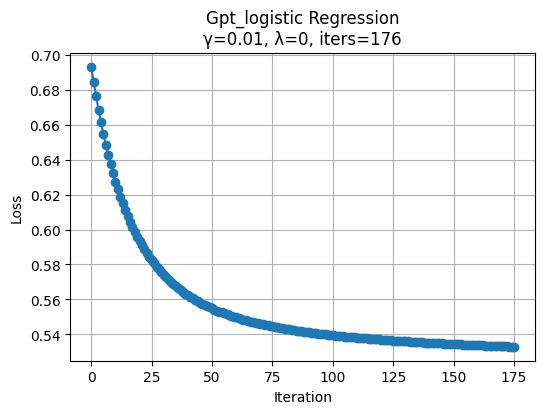


Final loss: 0.532955
Iterations: 176

Top 20 features by |weight|:

GENHLTH                    w = 0.10543
BPHIGH4                    w = -0.09667
TOLDHI2                    w = -0.09237
_AGE80                     w = 0.08281
_AGEG5YR                   w = 0.07979
CHCCOPD1                   w = -0.07755
_AGE_G                     w = 0.07133
_RFHYPE5                   w = 0.07016
SEX                        w = -0.06857
DIABETE3                   w = -0.06839
EMPLOY1                    w = 0.06799
PNEUVAC3                   w = -0.06753
_HCVU651                   w = 0.06692
_RFHLTH                    w = 0.06206
_AGE65YR                   w = 0.06163
CHCKIDNY                   w = -0.05703
QLACTLM2                   w = -0.05538
PHYSHLTH                   w = 0.05199
USEEQUIP                   w = -0.05014
SMOKE100                   w = -0.04989


In [10]:
valid_cols = ~np.isnan(x_data).all(axis=0)
x_data = x_data[:, valid_cols]
total_columns = [col for col, keep in zip(list(x_indices.keys()), valid_cols) if keep]
x_indices = {col: i for i, col in enumerate(total_columns)}

col_mean = np.nanmean(x_data, axis=0)
inds = np.where(np.isnan(x_data))
x_data[inds] = np.take(col_mean, inds[1])

# --- Standardize once ---
x_data = (x_data - np.mean(x_data, axis=0)) / np.std(x_data, axis=0)

# --- Prepare y ---
y = y_data[:,1].copy()
y[np.isnan(y)] = np.nanmean(y)
y = (y + 1) / 2  # convert -1,1 → 0,1
y = y.reshape(-1,1)

col_names = total_columns
tx = x_data
final_y = y

w3, loss3 = run_experiment(final_y, tx, col_names, 
                          kind="gpt_logistic", gamma=0.01, 
                            max_iters=300, lambda_=0, tol=1e-4)

Stopping early at iter 30 (Δloss_rel < tol)


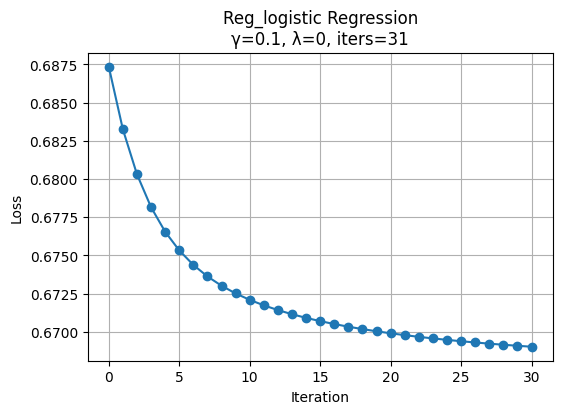


Final loss: 0.669022
Iterations: 31

Top 20 features by |weight|:

BPHIGH4                    w = -0.05966
_AGE80                     w = 0.05941
CHCCOPD1                   w = -0.05895
GENHLTH                    w = 0.05743
TOLDHI2                    w = -0.05709
SEX                        w = -0.04762
CHCKIDNY                   w = -0.04664
DIABETE3                   w = -0.04591
PNEUVAC3                   w = -0.04189
CVDSTRK3                   w = -0.04153
EMPLOY1                    w = 0.04150
USEEQUIP                   w = -0.03742
_RFHLTH                    w = 0.03525
VETERAN3                   w = -0.03257
PHYSHLTH                   w = 0.02924
SMOKE100                   w = -0.02550
QLACTLM2                   w = -0.02498
BPMEDS                     w = -0.02370
BLIND                      w = -0.02303
CHOLCHK                    w = -0.02097


In [ ]:
col_names = interesting_columns
tx = x_data_interested
final_y = y

# Example runs
#w1, loss1 = run_experiment(final_y, tx, col_names, 
                           #kind="logistic", gamma=0.1, 
                           #max_iters=100)

#w2, loss2 = run_experiment(final_y, tx, col_names, 
#                          kind="reg_logistic", gamma=0.1, 
#                         lambda_=0, max_iters=300, tol=1e-4)
w3, loss3 = run_experiment(final_y, tx, col_names, 
                          kind="gpt_logistic", gamma=0.1, 
                            max_iters=300, lambda_=2, tol=1e-4)

In [ ]:
print(f"\nFinal loss: {loss3:.6f}")
print("Weights:")
for c, val in zip(col_names, w3.flatten()):
    print(f"{c:20s}: {val: .5f}")



Final loss: 0.527567
Weights:
QLACTLM2            : -0.05974
_MISFRTN            : -0.00181
_FRUITEX            :  0.00057
_RFSEAT2            :  0.02625
DRNKANY5            :  0.01246
WTKG3               :  0.00438
TRNSGNDR            :  0.00098
FLUSHOT6            : -0.01531
ORNGDAY_            : -0.00014
PAFREQ2_            :  0.00460
INCOME2             : -0.05112
_VEGESUM            : -0.00642
CHECKUP1            : -0.02165
_VEGETEX            :  0.00693
MAXVO2_             : -0.01661
CHCOCNCR            : -0.01740
_MINAC11            : -0.00920
HIVTST6             :  0.03215
VETERAN3            : -0.08286
SEX                 : -0.17210
DRNK3GE5            :  0.02645
LMTJOIN3            :  0.01582
DIFFALON            : -0.01584
_RACE_G1            : -0.01458
_BMI5               : -0.01693
BPHIGH4             : -0.20321
FC60_               :  0.00017
CHOLCHK             : -0.08336
PADUR1_             : -0.01411
MEDCOST             : -0.02783
_LMTACT1            : -0.02960
_SMOKER3

In [27]:
def subset_run(x_data, y, x_indices, subset_cols, 
               kind="logistic", gamma=0.01, lambda_=0.0, 
               max_iters=200, tol=None):
    """
    Run (regularized) logistic regression only on a subset of variables.
    """
    cols_idx = [x_indices[c] for c in subset_cols]
    tx_sub = x_data[:, cols_idx]
    col_names = subset_cols
    w_init = np.zeros((tx_sub.shape[1], 1))

    if kind == "gpt_logistic":
        w, losses, _ = gptversion_logistic_regression(y, tx_sub, lambda_, w_init, max_iters, gamma, tol)
    elif kind == "logistic":
        w, losses, _ = logistic_regression(y, tx_sub, w_init, max_iters, gamma, tol)
    else:
        w, losses, _ = reg_logistic_regression(y, tx_sub, lambda_, w_init, max_iters, gamma, tol)

    plt.plot(losses)
    plt.title(f"{kind} regression on {len(subset_cols)} vars")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.show()

    print(f"\nFinal loss: {losses[-1]:.6f}")
    print("Weights:")
    for c, val in zip(col_names, w.flatten()):
        print(f"{c:20s}: {val: .5f}")

    return w, losses


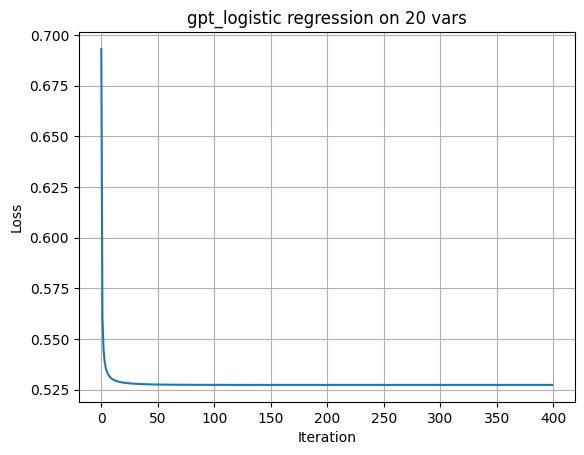


Final loss: 0.527274
Weights:
_AGE80              :  0.39881
BPHIGH4             : -0.20304
TOLDHI2             : -0.20004
GENHLTH             :  0.34659
SEX                 : -0.25430
EMPLOY1             :  0.10807
PNEUVAC3            : -0.10737
CHCCOPD1            : -0.15285
DIABETE3            : -0.08905
VETERAN3            : -0.04809
CHCKIDNY            : -0.09903
_RFHLTH             : -0.01473
CHOLCHK             : -0.08877
BLOODCHO            : -0.07096
SMOKE100            : -0.08748
CVDSTRK3            : -0.07011
QLACTLM2            : -0.06614
USEEQUIP            : -0.05949
HAVARTH3            : -0.03741
PHYSHLTH            :  0.03971


In [32]:
subset = ["_AGE80",
"BPHIGH4",
"TOLDHI2",
"GENHLTH",
"SEX",
"EMPLOY1",
"PNEUVAC3",
"CHCCOPD1",
"DIABETE3",
"VETERAN3",
"CHCKIDNY",
"_RFHLTH",
"CHOLCHK",
"BLOODCHO",
"SMOKE100",
"CVDSTRK3",
"QLACTLM2",
"USEEQUIP",
"HAVARTH3",
"PHYSHLTH",
]


w, losses = subset_run(x_data, y, x_indices, subset,
                       kind="gpt_logistic",
                       gamma=0.5, lambda_=0, max_iters=400)


In [42]:
def tune_hyperparameters(x_data, y, x_indices, subset_cols,
                         gammas=[0.001, 0.01, 0.05],
                         lambdas=[0.0, 0.01, 0.1],
                         max_iters_list=[200, 500],
                         tol=None,
                         regularized=True):
    """
    Try different gamma, lambda, and max_iters to find best performing setup.
    Works with or without regularization.
    """
    cols_idx = [x_indices[c] for c in subset_cols]
    tx_sub = x_data[:, cols_idx]
    w_init = np.zeros((tx_sub.shape[1], 1))

    results = []

    for gamma in gammas:
        for lambda_ in lambdas:
            for max_iters in max_iters_list:
                if regularized:
                    w, losses, _ = reg_logistic_regression(
                        y, tx_sub, lambda_=lambda_, initial_w=w_init,
                        max_iters=max_iters, gamma=gamma, tol=tol
                    )
                else:
                    w, losses, _ = logistic_regression(
                        y, tx_sub, initial_w=w_init,
                        max_iters=max_iters, gamma=gamma, tol=tol
                    )

                final_loss = float(losses[-1])
                max_w = float(np.max(np.abs(w)))
                mean_w = float(np.mean(np.abs(w)))
                results.append({
                    "gamma": gamma,
                    "lambda_": lambda_,
                    "max_iters": max_iters,
                    "final_loss": final_loss,
                    "max_w": max_w,
                    "mean_w": mean_w,
                    "w": w,
                    "losses": losses
                })

                print(f"γ={gamma:.4f}, λ={lambda_:.4f}, iters={max_iters:4d} → "
                      f"loss={final_loss:.6f}, max|w|={max_w:.4f}, mean|w|={mean_w:.4f}")

    # Sort results by final loss
    results.sort(key=lambda x: x["final_loss"])
    best = results[0]

    print("\n=== ✅ Best configuration (lowest loss) ===")
    print(f"γ={best['gamma']}, λ={best['lambda_']}, iters={best['max_iters']}, "
          f"loss={best['final_loss']:.6f}")

    # Plot top 3 loss curves
    import matplotlib.pyplot as plt
    plt.figure(figsize=(7, 4))
    for i, r in enumerate(results[:3]):
        plt.plot(r["losses"], label=f"γ={r['gamma']}, λ={r['lambda_']}, iters={r['max_iters']}")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Loss vs Iteration (Top 3 Configs)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Print weights for best config
    print("\n=== ⚙️ Best weights by feature ===")
    for name, val in zip(subset_cols, best["w"].flatten()):
        print(f"{name:<15s} : {val:+.4f}")

    return results


In [43]:
subset = ["_BMI5", "SEX", "EXERANY2", "BPHIGH4", "SMOKE100"]

results = tune_hyperparameters(
    x_data, y, x_indices,
    subset_cols=subset,
    gammas=[0.001, 0.005, 0.01],
    lambdas=[0.0, 0.01, 0.1],
    max_iters_list=[300, 600, 1000],
    tol=None,
    regularized=True
)

γ=0.0010, λ=0.0000, iters= 300 → loss=0.691576, max|w|=0.0175, mean|w|=0.0085
γ=0.0010, λ=0.0000, iters= 600 → loss=0.690269, max|w|=0.0336, mean|w|=0.0161
γ=0.0010, λ=0.0000, iters=1000 → loss=0.688861, max|w|=0.0530, mean|w|=0.0253
γ=0.0010, λ=0.0100, iters= 300 → loss=0.691580, max|w|=0.0174, mean|w|=0.0084
γ=0.0010, λ=0.0100, iters= 600 → loss=0.690284, max|w|=0.0334, mean|w|=0.0161


KeyboardInterrupt: 